# NB22 — Categorical Features and the Dummy-Variable Trap

> **StatQuest principle: regression only understands numbers — so we turn each category into its own little on/off switch.**

---

## The main ideas are:

1. A category like `city = {A, B, C}` cannot be used as 1, 2, 3 — that invents an order and equal spacing
2. **One-hot encoding** makes one 0/1 column per category
3. With an intercept, keeping ALL dummies creates **perfect multicollinearity** (the dummy-variable trap):
   the dummies always sum to 1 = the intercept column
4. Fix: drop one category — it becomes the **reference (baseline)**
5. Each dummy coefficient = **difference vs the baseline**, holding other features constant
6. In production use `OneHotEncoder` inside a `ColumnTransformer` + `Pipeline`


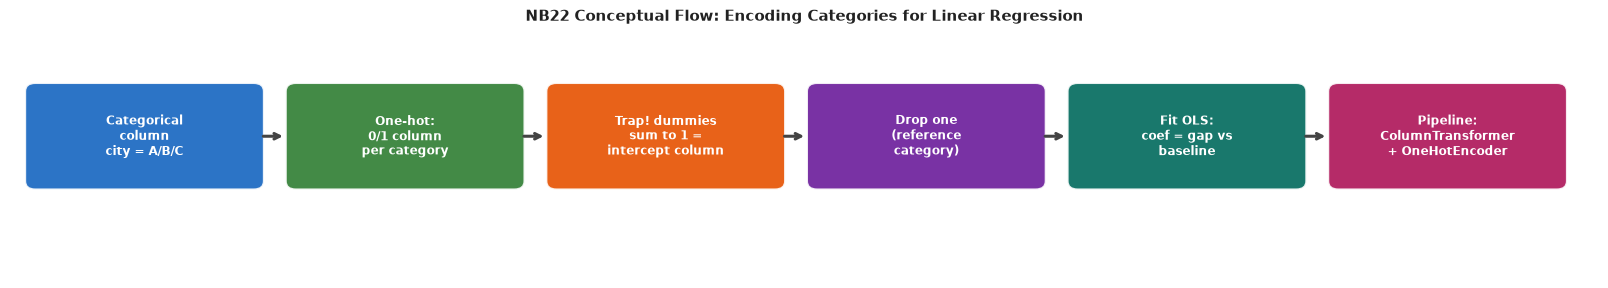

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

def flow_diagram(steps, title, colors=None, notes=None, figsize=(14, 2.8)):
    """Draw a horizontal flow diagram.  steps = list of strings."""
    n = len(steps)
    default_colors = [
        '#1565C0','#2E7D32','#E65100','#6A1B9A',
        '#00695C','#AD1457','#37474F','#4E342E',
        '#0277BD','#558B2F',
    ]
    colors = (colors or default_colors[:n]) + default_colors
    notes  = notes or [''] * n

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(-0.3, n * 3.1)
    ax.set_ylim(-1.2, 2.4)
    ax.axis('off')

    bw, bh = 2.6, 1.3
    for i, (step, color, note) in enumerate(zip(steps, colors, notes)):
        x = i * 3.1
        box = FancyBboxPatch((x, 0.2), bw, bh,
                             boxstyle="round,pad=0.12",
                             facecolor=color, edgecolor='white', linewidth=1.5, alpha=0.90)
        ax.add_patch(box)
        ax.text(x + bw/2, 0.2 + bh/2, step,
                ha='center', va='center', fontsize=8.5,
                color='white', fontweight='bold', multialignment='center')
        if note:
            ax.text(x + bw/2, 0.02, note,
                    ha='center', va='top', fontsize=7, color='#555', style='italic')
        if i < n - 1:
            ax.annotate('',
                xy=(x + bw + 0.38, 0.2 + bh/2),
                xytext=(x + bw + 0.08, 0.2 + bh/2),
                arrowprops=dict(arrowstyle='->', color='#444', lw=2.2))

    ax.set_title(title, fontsize=11, fontweight='bold', pad=6, color='#222')
    plt.tight_layout(pad=0.4)
    plt.show()

flow_diagram(
    steps=[
        'Categorical\ncolumn\ncity = A/B/C',
        'One-hot:\n0/1 column\nper category',
        'Trap! dummies\nsum to 1 =\nintercept column',
        'Drop one\n(reference\ncategory)',
        'Fit OLS:\ncoef = gap vs\nbaseline',
        'Pipeline:\nColumnTransformer\n+ OneHotEncoder',
    ],
    title='NB22 Conceptual Flow: Encoding Categories for Linear Regression',
    figsize=(16, 2.8),
)


## Step 1 — A synthetic housing dataset with a category

Price ($1000s) = 50 + 3·size(m²) + city effect + noise, with true city effects
**A = 0 (baseline), B = +90, C = +40** — the categories have no natural order.


In [2]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(22)
n = 300
city = rng.choice(['A', 'B', 'C'], size=n, p=[0.4, 0.35, 0.25])
size = rng.uniform(40, 160, n).round(0)
effect = pd.Series(city).map({'A': 0, 'B': 90, 'C': 40}).to_numpy()
price = 50 + 3 * size + effect + rng.normal(0, 20, n)

df = pd.DataFrame({'size_m2': size, 'city': city, 'price_k': price.round(1)})
print(df.head(6))
print("\nRows per city:", df['city'].value_counts().sort_index().to_dict())
print("\nMean price by city:")
print(df.groupby('city')['price_k'].mean().round(1))


   size_m2 city  price_k
0    149.0    A    462.3
1     50.0    A    210.2
2    109.0    A    357.2
3    151.0    B    585.5
4    122.0    B    505.3
5    134.0    C    465.6

Rows per city: {'A': 123, 'B': 114, 'C': 63}

Mean price by city:
city
A    344.6
B    429.2
C    393.0
Name: price_k, dtype: float64


## Step 2 — Why not just code A=1, B=2, C=3?

Label-encoding forces the model to assume B−A = C−B (equal steps) and one slope for "city".
The true gaps are A→B = +90 and B→C = −50 — not equal, not even the same sign.


In [3]:
import numpy as np
import statsmodels.api as sm

codes = df['city'].map({'A': 1, 'B': 2, 'C': 3})
X_bad = sm.add_constant(np.column_stack([df['size_m2'], codes]))
res_bad = sm.OLS(df['price_k'], X_bad).fit()
print("Label-encoded city (A=1, B=2, C=3):")
print(f"  one 'city' slope = {res_bad.params.iloc[2]:.2f} per step  -> forces A->B gap = B->C gap")
print(f"  R^2 = {res_bad.rsquared:.4f}")


Label-encoded city (A=1, B=2, C=3):
  one 'city' slope = 28.36 per step  -> forces A->B gap = B->C gap
  R^2 = 0.8757


## Step 3 — The dummy-variable trap, shown numerically

With an intercept plus **all three** dummies, column `const` = `A + B + C` exactly.
$X^TX$ is singular (rank deficient), so $(X^TX)^{-1}$ does not exist and the coefficients are not unique.


In [4]:
import numpy as np
import pandas as pd

D_all = pd.get_dummies(df['city'], dtype=float)                 # A, B, C
X_trap = np.column_stack([np.ones(n), df['size_m2'], D_all])
XtX = X_trap.T @ X_trap
print("Columns: const, size, A, B, C")
print("Check: A + B + C equals the constant column for every row:",
      bool(np.allclose(D_all.sum(axis=1), 1)))
print(f"rank(X) = {np.linalg.matrix_rank(X_trap)}  but number of columns = {X_trap.shape[1]}")
print(f"det(XtX) = {np.linalg.det(XtX):.3e}")
print(f"condition number of XtX = {np.linalg.cond(XtX):.3e}   (infinite in exact arithmetic)")

# Two different coefficient vectors give IDENTICAL predictions:
b1 = np.linalg.lstsq(X_trap, df['price_k'], rcond=None)[0]
shift = np.array([10, 0, -10, -10, -10])        # +10 to intercept, -10 to every dummy
b2 = b1 + shift
print("\nSolution 1:", b1.round(3))
print("Solution 2:", b2.round(3))
print("Max prediction difference:", float(np.abs(X_trap @ b1 - X_trap @ b2).max().round(10)))
print("-> infinitely many 'best' fits: the coefficients are meaningless")


Columns: const, size, A, B, C
Check: A + B + C equals the constant column for every row: True
rank(X) = 4  but number of columns = 5
det(XtX) = 0.000e+00
condition number of XtX = 2.458e+18   (infinite in exact arithmetic)

Solution 1: [ 70.722   2.971 -18.92   70.321  19.321]
Solution 2: [ 80.722   2.971 -28.92   60.321   9.321]
Max prediction difference: 0.0
-> infinitely many 'best' fits: the coefficients are meaningless


## Step 4 — Drop one category: the reference level

`drop_first=True` drops **A**. Now:
- intercept = expected price for city **A** (at size 0)
- `B` coefficient = how much more B costs than A, **same size**
- `C` coefficient = how much more C costs than A, same size


In [5]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

D = pd.get_dummies(df['city'], drop_first=True, dtype=float)   # B, C
X_ok = sm.add_constant(pd.concat([df[['size_m2']], D], axis=1))
res = sm.OLS(df['price_k'], X_ok).fit()
print(f"rank(X) = {np.linalg.matrix_rank(X_ok)} = number of columns {X_ok.shape[1]}  -> unique solution\n")
print(res.summary().tables[1])
print(f"\nR^2 = {res.rsquared:.4f}  (label-encoded version: {res_bad.rsquared:.4f})")
print(f"\nInterpretation (true values: B=+90, C=+40):")
print(f"  B vs A: {res.params['B']:+.2f}k   C vs A: {res.params['C']:+.2f}k   per m2: {res.params['size_m2']:.3f}k")
print(f"  C vs B: {res.params['C'] - res.params['B']:+.2f}k  (difference of the two dummies)")


rank(X) = 4 = number of columns 4  -> unique solution

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         51.8022      3.836     13.506      0.000      44.254      59.351
size_m2        2.9711      0.034     86.852      0.000       2.904       3.038
B             89.2404      2.637     33.842      0.000      84.051      94.430
C             38.2414      3.144     12.164      0.000      32.054      44.429

R^2 = 0.9667  (label-encoded version: 0.8757)

Interpretation (true values: B=+90, C=+40):
  B vs A: +89.24k   C vs A: +38.24k   per m2: 2.971k
  C vs B: -51.00k  (difference of the two dummies)


## Step 5 — Changing the baseline changes the numbers, not the model

Choosing **C** as the reference gives different coefficients but **identical predictions and R²**.
Pick the baseline that makes the story easiest to tell (e.g. the most common category).


In [6]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

D_c = pd.get_dummies(df['city'], dtype=float).drop(columns='C')   # keep A, B; C = reference
res_c = sm.OLS(df['price_k'], sm.add_constant(pd.concat([df[['size_m2']], D_c], axis=1))).fit()
print("Reference = C:", res_c.params.round(2).to_dict())
print("Reference = A:", res.params.round(2).to_dict())
print(f"\nSame R^2: {res_c.rsquared:.6f} vs {res.rsquared:.6f}")
print("Max prediction difference:", float(np.abs(res_c.fittedvalues - res.fittedvalues).max().round(8)))


Reference = C: {'const': 90.04, 'size_m2': 2.97, 'A': -38.24, 'B': 51.0}
Reference = A: {'const': 51.8, 'size_m2': 2.97, 'B': 89.24, 'C': 38.24}

Same R^2: 0.966652 vs 0.966652
Max prediction difference: 0.0


## Step 6 — The production way: ColumnTransformer + OneHotEncoder

`OneHotEncoder(drop='first', handle_unknown='ignore')` learns the categories on the **training** data only
(no leakage) and, with `handle_unknown='ignore'`, maps an unseen category to all-zeros instead of crashing.


In [7]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(df[['size_m2', 'city']], df['price_k'],
                                          test_size=0.25, random_state=0)
pre = ColumnTransformer([
    ('num', 'passthrough', ['size_m2']),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), ['city']),
])
pipe = Pipeline([('pre', pre), ('ols', LinearRegression())]).fit(X_tr, y_tr)
names = pipe.named_steps['pre'].get_feature_names_out()
print("Features:", list(names))
print("Coefficients:", dict(zip(names, pipe.named_steps['ols'].coef_.round(2))))
print(f"Intercept: {pipe.named_steps['ols'].intercept_:.2f}")
print(f"Test R^2: {pipe.score(X_te, y_te):.4f}")
new = pd.DataFrame({'size_m2': [100, 100, 100], 'city': ['A', 'C', 'Z']})
print("\nPredictions for 100 m2 in A, C and an unseen city 'Z' (treated like the baseline):")
import warnings
with warnings.catch_warnings():
    warnings.simplefilter('ignore')      # sklearn warns that 'Z' was unseen -> encoded as all zeros
    print(pipe.predict(new).round(1))


Features: ['num__size_m2', 'cat__city_B', 'cat__city_C']
Coefficients: {'num__size_m2': np.float64(2.95), 'cat__city_B': np.float64(87.62), 'cat__city_C': np.float64(39.82)}
Intercept: 55.18
Test R^2: 0.9598

Predictions for 100 m2 in A, C and an unseen city 'Z' (treated like the baseline):
[349.9 389.7 349.9]


## Key Takeaways

| Concept | What to remember |
|---|---|
| Label encoding | A=1, B=2, C=3 invents order and equal spacing — wrong for nominal categories |
| One-hot | one 0/1 column per category |
| Dummy-variable trap | intercept + all k dummies → columns sum to the constant → singular $X^TX$, non-unique coefficients |
| Fix | drop one category (k−1 dummies); it becomes the reference |
| Interpretation | dummy coefficient = difference vs the reference category, other features held constant |
| Baseline choice | changes coefficients, never predictions or R² |
| Production | `OneHotEncoder(drop='first', handle_unknown='ignore')` inside a `ColumnTransformer` + `Pipeline` |
| Note | Ridge/Lasso can keep all k dummies (the penalty makes the solution unique) — but plain OLS cannot |
